In [5]:
# Implementation3: Constructing a Log Likelihood Estimator inspired by Nguyen 

import numpy as np

In [1]:
import numpy as np
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

# Define Gaussian Kernel
def gaussian_kernel(X, Y, sigma=1.0):
    return rbf_kernel(X, Y, gamma=1/(2*sigma**2))

# Dual objective function as in Lemma 5
def dual_objective(alpha, X, Y, lambda_n, kernel_func):
    n = len(X)
    term1 = -1 - np.mean(np.log(n * alpha))
    term2 = (alpha @ kernel_func(Y, Y) @ alpha) / (2 * lambda_n)
    term3 = np.sum(kernel_func(X, X)) / (2 * lambda_n * n**2)
    term4 = -(np.sum(kernel_func(X, Y) @ alpha)) / (lambda_n * n)

    return -(term1 + term2 + term3 + term4)

# Estimation function for g_hat and KL divergence
def estimate_llr_kl(X_samples, Y_samples, lambda_n=0.01, sigma=1.0):
    n = len(X_samples)

    kernel_func = lambda A, B: gaussian_kernel(A, B, sigma)

    # Initial guess for alpha
    alpha_init = np.ones(n) / n

    # Bounds: alpha > 0
    bounds = [(1e-8, None)] * n

    # Optimization
    result = minimize(dual_objective, alpha_init, args=(X_samples, Y_samples, lambda_n, kernel_func),
                      method='L-BFGS-B', bounds=bounds)

    alpha_hat = result.x

    # Calculate the estimator g_hat(x) for new points x as per equation (42)
    def g_hat(x_new):
        term_Y = kernel_func(x_new, Y_samples) @ alpha_hat
        term_X = kernel_func(x_new, X_samples).mean(axis=1)
        return (term_Y - term_X) / lambda_n

    # KL divergence estimator as per equation (43)
    kl_estimate = np.mean(-np.log(n * alpha_hat))

    return g_hat, kl_estimate

# Example usage with random data
np.random.seed(42)
X_samples = np.random.normal(0, 1, (100, 1))  # samples from Q
Y_samples = np.random.normal(1, 1, (100, 1))  # samples from P

g_hat_func, kl_divergence = estimate_llr_kl(X_samples, Y_samples)
print(f"Estimated KL Divergence: {kl_divergence}")

# Example evaluation at new points
new_points = np.linspace(-3, 3, 100).reshape(-1, 1)
estimated_llr = g_hat_func(new_points)

Estimated KL Divergence: -172.67236785005522


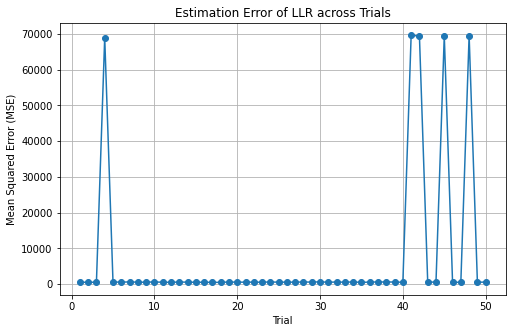

Average MSE over 50 trials: 7449.723938


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

# Define Gaussian Kernel
def gaussian_kernel(X, Y, sigma=1.0):
    return rbf_kernel(X, Y, gamma=1/(2*sigma**2))

# Dual objective function
def dual_objective(alpha, X, Y, lambda_n, kernel_func):
    n = len(X)
    term1 = -1 - np.mean(np.log(n * alpha))
    term2 = (alpha @ kernel_func(Y, Y) @ alpha) / (2 * lambda_n)
    term3 = np.sum(kernel_func(X, X)) / (2 * lambda_n * n**2)
    term4 = -(np.sum(kernel_func(X, Y) @ alpha)) / (lambda_n * n)
    return -(term1 + term2 + term3 + term4)

# Estimation function for g_hat and KL divergence
def estimate_llr_kl(X_samples, Y_samples, lambda_n=0.01, sigma=1.0):
    n = len(X_samples)
    kernel_func = lambda A, B: gaussian_kernel(A, B, sigma)
    alpha_init = np.ones(n) / n
    bounds = [(1e-8, None)] * n

    result = minimize(dual_objective, alpha_init, args=(X_samples, Y_samples, lambda_n, kernel_func),
                      method='L-BFGS-B', bounds=bounds)

    alpha_hat = result.x

    def g_hat(x_new):
        term_Y = kernel_func(x_new, Y_samples) @ alpha_hat
        term_X = kernel_func(x_new, X_samples).mean(axis=1)
        return (term_Y - term_X) / lambda_n

    kl_estimate = np.mean(-np.log(n * alpha_hat))

    return g_hat, kl_estimate

# Exact log likelihood ratio function for Gaussian P ~ N(mu1, 1), Q ~ N(mu2, 1)
def exact_llr(x, mu1=1.0, mu2=0.0):
    return (mu2**2 - mu1**2 + 2*(mu1 - mu2)*x) / 2

# Parameters
mu1, mu2 = 1.0, 0.0
sigma = 1.0
lambda_n = 0.01
n_samples = 100
n_trials = 50

errors = []

for trial in range(n_trials):
    X_samples = np.random.normal(mu2, 1, (n_samples, 1))  # samples from Q
    Y_samples = np.random.normal(mu1, 1, (n_samples, 1))  # samples from P

    g_hat_func, _ = estimate_llr_kl(X_samples, Y_samples, lambda_n, sigma)

    # Evaluate at test points
    test_points = np.linspace(-3, 3, 100).reshape(-1, 1)
    estimated_llr = np.log(np.clip(g_hat_func(test_points), 1e-8, None))
    true_llr = exact_llr(test_points, mu1, mu2)

    error = np.mean((estimated_llr - true_llr)**2)
    errors.append(error)

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_trials + 1), errors, marker='o')
plt.xlabel('Trial')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Estimation Error of LLR across Trials')
plt.grid(True)
plt.show()

print(f"Average MSE over {n_trials} trials: {np.mean(errors):.6f}")


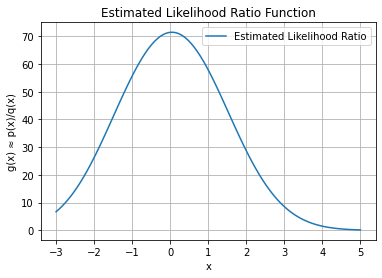

In [6]:
import numpy as np
from scipy.optimize import minimize
from sklearn.metrics.pairwise import rbf_kernel

class LikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-3):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None
        self.X_q = None

    def fit(self, X_p, X_q):
        """
        Estimate the likelihood ratio g(x) = p(x)/q(x)
        from samples X_p ~ P and X_q ~ Q.
        """
        n_p = X_p.shape[0]
        n_q = X_q.shape[0]

        self.X_p = X_p
        self.X_q = X_q

        # Compute kernel matrices
        K_pp = rbf_kernel(X_p, X_p, gamma=1/(2*self.sigma**2))
        K_qp = rbf_kernel(X_q, X_p, gamma=1/(2*self.sigma**2))

        # Objective for dual problem (to solve for alpha)
        def dual_obj(alpha):
            term1 = -np.sum(np.log(alpha)) / n_p
            term2 = 0.5 / self.lambda_reg * (alpha @ K_pp @ alpha)
            term3 = -1.0 / (self.lambda_reg * n_q) * np.sum(K_qp @ alpha)
            return term1 + term2 + term3

        # Constraints: alpha > 0
        constraints = ({'type': 'ineq', 'fun': lambda a: a - 1e-8})

        # Initial guess
        alpha0 = np.ones(n_p) / n_p

        result = minimize(dual_obj, alpha0, method='SLSQP', constraints=constraints)
        if not result.success:
            raise ValueError("Optimization failed: " + result.message)

        self.alpha = result.x

    def predict(self, X):
        """
        Predict the likelihood ratio g(x) for new samples X.
        """
        if self.alpha is None:
            raise ValueError("Model has not been fitted yet.")

        # Compute kernel between new X and training X_p
        K_Xp = rbf_kernel(X, self.X_p, gamma=1/(2*self.sigma**2))

        # The estimated likelihood ratio g(x) = (K_Xp @ alpha) / lambda_reg
        g_x = (K_Xp @ self.alpha) / self.lambda_reg
        return g_x

# Example usage:
if __name__ == "__main__":
    # Generate synthetic data
    np.random.seed()
    X_p = np.random.normal(loc=1.0, scale=1.0, size=(100, 1))  # P ~ N(1, 1)
    X_q = np.random.normal(loc=0.0, scale=1.0, size=(100, 1))  # Q ~ N(0, 1)

    # Fit the estimator
    model = LikelihoodRatioEstimator(sigma=1.0, lambda_reg=1e-2)
    model.fit(X_p, X_q)

    # Predict the likelihood ratio on new points
    X_test = np.linspace(-3, 5, 100).reshape(-1, 1)
    llr_estimates = model.predict(X_test)

    # Simple plot (optional)
    import matplotlib.pyplot as plt

    plt.plot(X_test, llr_estimates, label='Estimated Likelihood Ratio')
    plt.xlabel('x')
    plt.ylabel('g(x) ≈ p(x)/q(x)')
    plt.title('Estimated Likelihood Ratio Function')
    plt.legend()
    plt.grid(True)
    plt.show()
